# EMQA_L5_premium

**Ex-post forward premium of one-month-ahead products**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_premium/EMQA_L5_premium.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Forward minus realised spot for monthly baseload products bought one month ahead.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
def premium_table(base):
    """Ex-post forward premium of every baseload product fully delivered by the cut-off: F - realised mean spot."""
    b = base[base['delivery_end'] <= END].copy()
    b['S'] = [realised(s, e) for s, e in zip(b['delivery_start'], b['delivery_end'])]
    b = b.dropna(subset=['S'])
    b['prem'] = b['price_eur_mwh'] - b['S']
    b['lr'] = np.log(b['S'] / b['price_eur_mwh'])
    b['T'] = ((b['delivery_start'] + (b['delivery_end'] - b['delivery_start']) / 2) - b['auction_date']).dt.days / 365.25
    return b


PT = premium_table(BASE)
# monthly products traded in the month before delivery
M1 = PT[(PT['kind'] == 'M') & (PT['lead_m'] == 1)]

In [6]:
import statsmodels.api as sm


def nw_t(x, lags=3):
    """Mean of x with a Newey-West (HAC, 3 lags) standard error: mean, se, t, p."""
    x = np.asarray(x, float)
    r = sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(r.params[0]), float(r.bse[0]), float(r.tvalues[0]), float(r.pvalues[0])


MP = M1.groupby('delivery_start').apply(lambda g: pd.Series({'F': vwap(g), 'S': g['S'].iloc[0], 'n': len(g)}))
MP['prem'] = MP['F'] - MP['S']
mu, se, tt, pp = nw_t(MP['prem'])
show('delivery months', len(MP), 'prem.m1.n', 'd')
show('first delivery month', MP.index.min().strftime('%Y-%m'), 'prem.m1.first')
show('last delivery month', MP.index.max().strftime('%Y-%m'), 'prem.m1.last')
show('mean premium F - S, EUR/MWh', mu, 'prem.m1.mean', '.2f')
show('HAC standard error', se, 'prem.m1.se', '.2f')
show('t statistic', tt, 'prem.m1.t', '.2f')
show('p-value', pp, 'prem.m1.p', '.3f')
show('median premium, EUR/MWh', MP['prem'].median(), 'prem.m1.median', '.1f')
show('share of months with F > S, %', 100 * (MP['prem'] > 0).mean(), 'prem.m1.pos_share', '.1f')
gm = MP[MP.index >= '2023-01-01']
a, _, c, p = nw_t(gm['prem'])
show('from 2023: mean premium, EUR/MWh', a, 'prem.m1_post.mean', '.2f')
show('from 2023: t statistic', c, 'prem.m1_post.t', '.2f')

delivery months                                                      30   [prem.m1.n]
first delivery month                                            2020-08   [prem.m1.first]
last delivery month                                             2026-08   [prem.m1.last]
mean premium F - S, EUR/MWh                                        5.16   [prem.m1.mean]
HAC standard error                                                12.39   [prem.m1.se]
t statistic                                                        0.42   [prem.m1.t]
p-value                                                           0.677   [prem.m1.p]
median premium, EUR/MWh                                            -0.3   [prem.m1.median]
share of months with F > S, %                                      50.0   [prem.m1.pos_share]
from 2023: mean premium, EUR/MWh                                  24.47   [prem.m1_post.mean]
from 2023: t statistic                                             1.51   [prem.m1_post.t]


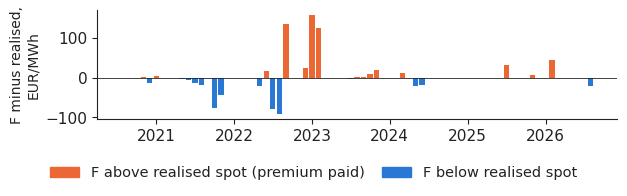

In [7]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.bar(MP.index, MP['prem'], width=25, color=[PAL['DE_LU'] if v > 0 else PAL['RO'] for v in MP['prem']])
ax.axhline(0, color='#222222', lw=0.6)
hnd = [Patch(color=PAL['DE_LU'], label='F above realised spot (premium paid)'),
       Patch(color=PAL['RO'], label='F below realised spot')]
ax.set_ylabel('F minus realised,\nEUR/MWh', fontsize=10)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, handles=hnd, labels=[h.get_label() for h in hnd], ncol=2)
save_chart(fig, 'premium')